<a href="https://colab.research.google.com/github/bvd006/SE/blob/main/SE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
!pip install pesq pystoi audiomentations nnAudio==0.3.4 "torchmetrics[audio]" #attenuate

In [2]:
#!pip install mamba-ssm[causal-conv1d] --no-build-isolation
#!MAMBA_FORCE_BUILD=TRUE pip install --no-cache-dir --force-reinstall git+https://github.com/state-spaces/mamba.git --no-build-isolation
#import mamba_ssm

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from IPython.display import Audio, display
import os
from os import path
import soundfile as sf
import librosa
import torchaudio
import torchaudio.functional as F
import re
import json
from torch.optim import AdamW
from audiomentations import Compose, TimeStretch, PitchShift, Shift, PolarityInversion
import numpy as np
from google.colab import drive
from torchmetrics.functional.audio.dnsmos import (
    deep_noise_suppression_mean_opinion_score
)

In [4]:
from torch.utils.data import Dataset
import gc
class BaseDenoisingDataset(Dataset):
  def collate_fn(self, batch, crop_len=2, return_lengths=False):
    if self.mode == 'waveform':
      noisy, clean = map(list, zip(*batch))

      for i in range(len(noisy)):
        if crop_len and noisy[i].shape[0] > 16_000*crop_len:
          #dur = np.random.randint(16_000, 16_000 * 2)
          dur = 16_000 * crop_len
          beg = np.random.randint(0, noisy[i].shape[0] - dur)
          noisy[i] = noisy[i][beg:beg + dur]
          clean[i] = clean[i][beg:beg + dur]

      lengths = torch.tensor(
      [x.shape[0] for x in noisy],
      dtype=torch.long
      )

      length = max(v.shape[0] for v in noisy)
      length += (self.addition - length%self.addition)%self.addition

      noisy_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[0]))
          for val in noisy
      ])

      clean_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[0]))
          for val in clean
      ])
      if return_lengths:
        return noisy_pad, clean_pad, lengths
      return noisy_pad, clean_pad

    if self.mode == 'spectrogram':
      time_axis = 2
      noisy, clean = map(list, zip(*batch))

      for i in range(len(noisy)):
        if crop_len and noisy[i].shape[time_axis] > 16_000*crop_len/256:
          #dur = np.random.randint(int(16_000/256), int(16_000 * 2/256))
          dur = int(16_000 * crop_len/256)
          beg = np.random.randint(0, noisy[i].shape[time_axis] - dur)
          mask = torch.zeros_like(noisy[i], dtype=torch.bool)
          mask[:,:,beg: beg + dur] = 1
          old_shape = noisy[i].shape
          noisy[i] = noisy[i][mask].reshape((old_shape[0], old_shape[1], -1))
          clean[i] = clean[i][mask].reshape((old_shape[0], old_shape[1], -1))

      lengths = torch.tensor(
      [x.shape[time_axis] for x in noisy],
      dtype=torch.long
      )
      length = max(v.shape[time_axis] for v in noisy)
      length += (self.addition - length%self.addition)%self.addition
      noisy_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[time_axis]))
          for val in noisy
      ])

      clean_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[time_axis]))
          for val in clean
      ])
      if return_lengths:
        return noisy_pad, clean_pad, lengths
      return noisy_pad, clean_pad

  def display(self, i, mode='clean', autoplay = True):
    idx = 1 if mode == 'clean' else 0
    display(Audio(self[i][idx], rate=self.sr, autoplay=autoplay, normalize=False))

  def display_augmentations(self, mode = 'clean'):
    idx = 1 if mode == 'clean' else 0
    if self.dual_aug == None:
      print('No augmentations')
    # display current?

    i = np.random.randint(len(self))

    self.no_augm_mode = True
    initial = self[i][idx].numpy()
    self.no_augm_mode = False

    print('Innitaial audio')
    display(Audio(initial, rate=self.sr, normalize=False))

    print('Time Stretch display')
    for rate in [0.5, 0.9, 1.1, 1.5]:
      print('Rate - ', rate)
      augmented = TimeStretch(min_rate=rate, max_rate=rate, p=1.0)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))

    print('Pitch Shift display')

    for rate in [-3, -2, -1, 1, 2, 3]:
      print('semitones - ', rate)
      augmented = PitchShift(min_semitones=rate, max_semitones=rate, p=1)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))

    print('Polarity Inversion display')

    for rate in ['']:
      print('Inverted sygnal is audibly unextinguishable')
      augmented = PolarityInversion(p=1)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))


  def arr_to_sp(self, arr):
    raw_spectr = librosa.stft(arr, n_fft=512, hop_length=256, win_length=512)
    spectr = torch.stack((torch.tensor(raw_spectr.real),
                          torch.tensor(raw_spectr.imag)))
    return spectr


from datasets import load_dataset, Audio as datasets_Audio
class FolderDenoisingDataset(BaseDenoisingDataset):
  def __init__(self, data_path, train = True, sr = 16000, mode = 'waveform', dual_aug = None, mono_aug = None):
    self.sr = sr
    self.mode = mode
    self.dual_aug = dual_aug
    self.mono_aug = mono_aug
    self.no_augm_mode = False
    self.addition = 256
    self.train = train
    self.path = data_path
    self.path_clean = path.join(data_path, 'train' if train else 'test', 'clean')
    self.path_noisy = path.join(data_path, 'train' if train else 'test', 'noisy')
    self.files = sorted(
        f for f in os.listdir(self.path_clean)
        if f.lower().endswith(".wav")
    )
  def __getitem__(self, i):
    name = self.files[i]
    noisy = librosa.load(path.join(self.path_noisy, name), sr = self.sr)[0]
    clean = librosa.load(path.join(self.path_clean, name), sr = self.sr)[0]
    if self.dual_aug != None and not self.no_augm_mode:
      self.dual_aug.randomize_parameters(samples=noisy, sample_rate=self.sr)
      self.dual_aug.freeze_parameters()
      noisy = self.dual_aug(noisy, self.sr)
      clean = self.dual_aug(clean, self.sr)
      self.dual_aug.unfreeze_parameters()
    if self.mono_aug != None and not self.no_augm_mode:
      noisy = self.mono_aug(noisy, self.sr)
    if self.mode == 'waveform':
      return torch.tensor(noisy), torch.tensor(clean)
    elif self.mode == 'spectrogram':
      return self.arr_to_sp(noisy), self.arr_to_sp(clean)

  def __len__(self):
    return len(self.files)

  def get_all_durations(self):
    cnt = {}
    for i in tqdm(range(len(self))):
      info = sf.info(path.join(self.path_noisy, self.files[i]))
      dur = round(info.duration, 1)
      cnt[dur] = cnt.get(dur, 0) + 1
    return cnt

class HG_DenoisingDataset(BaseDenoisingDataset):
    def __init__(self, train=True, sr=16000, mode='waveform', dual_aug=None, mono_aug=None):
        self.sr = sr
        self.train = train
        self.mode = mode
        self.dual_aug = dual_aug
        self.mono_aug = mono_aug
        self.no_augm_mode = False
        self.addition = 256

        split_name = "train" if train else "test"
        self.dataset = load_dataset("JacobLinCool/VoiceBank-DEMAND-16k", split=split_name)

        self.dataset = self.dataset.cast_column("clean", datasets_Audio(sampling_rate=sr))
        self.dataset = self.dataset.cast_column("noisy", datasets_Audio(sampling_rate=sr))


    def __getitem__(self, i):
        item = self.dataset[i]
        noisy = item["noisy"]["array"]
        clean = item["clean"]["array"]

        if noisy.ndim > 1:
            noisy = noisy.mean(axis=1)
        if clean.ndim > 1:
            clean = clean.mean(axis=1)

        if self.dual_aug is not None and not self.no_augm_mode:
            self.dual_aug.randomize_parameters(samples=noisy, sample_rate=self.sr)
            self.dual_aug.freeze_parameters()
            noisy = self.dual_aug(noisy, self.sr)
            clean = self.dual_aug(clean, self.sr)
            self.dual_aug.unfreeze_parameters()

        if self.mono_aug is not None and not self.no_augm_mode:
            noisy = self.mono_aug(noisy, self.sr)

        if self.mode == 'waveform':
            return torch.tensor(noisy, dtype=torch.float32), torch.tensor(clean, dtype=torch.float32)
        elif self.mode == 'spectrogram':
            return self.arr_to_sp(noisy), self.arr_to_sp(clean)
        else:
            raise ValueError(f"Unknown mode: {self.mode}")

    def __len__(self):
        return len(self.dataset)

    def get_all_durations(self):
        cnt = {}
        for i in tqdm(range(len(self))):
            item = self.dataset[i]
            dur = round(len(item["noisy"]["array"]) / self.sr, 1)
            cnt[dur] = cnt.get(dur, 0) + 1
        return cnt

In [5]:
drive.mount('/content/drive')
#!cp /content/drive/MyDrive/voicebank_plus_demand_16k /content/data -r

Mounted at /content/drive


In [6]:
from audiomentations import Compose, TimeStretch, PitchShift, Shift, PolarityInversion
import numpy as np

standart_dual = Compose([
    PolarityInversion(p=0.5),
    TimeStretch(min_rate=0.9, max_rate=1.1, p=0.5),
    PitchShift(min_semitones=-2, max_semitones=2, p=0.6),
    #Shift(p=0.5),
])


In [7]:
sampling_rate = 16000
my_path = "/content/data"
#training_dataset = BaseDenoisingDataset(my_path, sr=sampling_rate, dual_aug=standart_dual)
training_dataset = HG_DenoisingDataset(dual_aug=None)
training_dataset.display(9000, 'clean')

README.md:   0%|          | 0.00/652 [00:00<?, ?B/s]

data/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  444MB            

data/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

data/train-00001-of-00005.parquet: downloading bytes:           |  0.00B            

...

data/train-00004-of-00005.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  132MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11572 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/824 [00:00<?, ? examples/s]

In [8]:
'''
import seaborn as sns
plt.figure(figsize=(40, 5))
d = training_dataset.get_all_durations()
sns.barplot(d)
print(min(d.keys()), max(d.keys()))
s = sum([k * v for k, v in d.items()])
print(s/3600)
'''


'\nimport seaborn as sns\nplt.figure(figsize=(40, 5))\nd = training_dataset.get_all_durations()\nsns.barplot(d)\nprint(min(d.keys()), max(d.keys()))\ns = sum([k * v for k, v in d.items()])\nprint(s/3600)\n'

In [9]:
from torch.utils.data import random_split
training_part, evaluation_part = random_split(training_dataset, [0.9, 0.1])

from torch.utils.data import DataLoader
# тестовые данные
evaluation_data = DataLoader(evaluation_part,
                           batch_size=24,
                           shuffle=False,
                           num_workers=2,
                           pin_memory=torch.cuda.is_available(),
                           prefetch_factor=6,
                           collate_fn=evaluation_part.dataset.collate_fn)
# обучающая выборка
train_data = DataLoader(training_part,
                           batch_size=8,
                           shuffle=True,
                           num_workers=2,
                           pin_memory=torch.cuda.is_available(),
                           prefetch_factor=16,
                           drop_last=True,
                           collate_fn=training_part.dataset.collate_fn)

# данные для оценки качества на обучающей выборке
train_representation, _ = random_split(training_part, [0.11, 0.89])
shortened_train_data = DataLoader(train_representation,
                                  batch_size=24,
                                  shuffle=False,
                                  num_workers=2,
                                  pin_memory=torch.cuda.is_available(),
                                  prefetch_factor=6,
                                  collate_fn=train_representation.dataset.dataset.collate_fn)

#my_path_test = "/content/data"
#my_path_test = "/content/drive/MyDrive/voicebank_demand_16k"

test_dataset = HG_DenoisingDataset(sr=sampling_rate, train=False)

test_data = DataLoader(test_dataset,
                        batch_size=1,
                        shuffle=False,
                        num_workers=2,
                        pin_memory=torch.cuda.is_available(),
                        prefetch_factor=6,
                        drop_last=True,
                        collate_fn=test_dataset.collate_fn)

In [10]:
from torch.utils.data import Dataset, DataLoader, Subset
from functools import partial

dnsmos_evaluation_data = DataLoader(
    evaluation_part,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=partial(
        training_dataset.collate_fn,
        crop_len=False,
        return_lengths=True
    )
)

dnsmos_test_data = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=partial(
        training_dataset.collate_fn,
        crop_len=False,
        return_lengths=True
    )
)

In [11]:
from pesq import pesq
from pystoi import stoi
from joblib import Parallel, delayed

def pesq_batch(sr, Y, X):
    X = X.detach().cpu().numpy() if X.is_cuda else X.detach().numpy()
    Y = Y.detach().cpu().numpy() if Y.is_cuda else Y.detach().numpy()

    pesq_score = Parallel(n_jobs=-1)(delayed(pesq)(sr, y, x, on_error=1)
                  for x, y in zip(Y, X))
    pesq_score = np.array(pesq_score)
    return pesq_score

def stoi_batch(Y, X, sr):
  X = X.detach().cpu().numpy() if X.is_cuda else X.detach().numpy()
  Y = Y.detach().cpu().numpy() if Y.is_cuda else Y.detach().numpy()
  stoi_score = Parallel(n_jobs=-1)(delayed(stoi)(y, x, sr)
                  for x, y in zip(Y, X))
  stoi_score = np.array(stoi_score)
  return stoi_score

def dnsmos_batch(preds, lengths=None, sr=16000, device='cpu', personalized=False):
    if preds.ndim == 1:
        preds = preds.unsqueeze(0)

    preds = preds.detach().float().cpu()

    if lengths is None:
        lengths = [preds.shape[-1]] * preds.shape[0]
    else:
        lengths = torch.as_tensor(lengths).reshape(-1).tolist()

    scores = []

    for audio, length in zip(preds, lengths):
        audio = audio[:int(length)].contiguous()

        score = deep_noise_suppression_mean_opinion_score(
            preds=audio,
            fs=sr,
            personalized=personalized,
            device=device
        )

        scores.append(score.float())

    return torch.stack(scores, dim=0)


In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import nnAudio

class attennuate_loss_mod(nn.Module):
    def __init__(self, freq_weight=0.0011, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.scales = scales
        for n_fft in scales:
            self.register_buffer(f'window_{n_fft}', torch.hann_window(n_fft))

    def stft_complex(self, x, res, window):
        return torch.stft(
            x,
            n_fft=res,
            hop_length=res//2,
            window=window,
            return_complex=True
        )

    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for v in self.scales:
          window = getattr(self, f'window_{v}')
          input_stft = self.stft_complex(input, v, window)
          target_stft = self.stft_complex(target, v, window)

          input_stft = torch.abs(input_stft)
          target_stft = torch.abs(target_stft)

          freq_loss += torch.nn.functional.mse_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if torch.rand(1) > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

class attennuate_loss_phase(nn.Module):
    def __init__(self, freq_weight=0.0011, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.scales = scales
        for n_fft in scales:
            self.register_buffer(f'window_{n_fft}', torch.hann_window(n_fft))

    def stft_complex(self, x, res, window):
        return torch.stft(
            x,
            n_fft=res,
            hop_length=res//2,
            window=window,
            return_complex=True
        )

    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for v in self.scales:
          window = getattr(self, f'window_{v}')
          input_stft = self.stft_complex(input, v, window)
          target_stft = self.stft_complex(target, v, window)

          input_stft = torch.view_as_real(input_stft)
          target_stft = torch.view_as_real(target_stft)

          freq_loss += torch.nn.functional.mse_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if torch.rand(1) > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

class attennuate_loss_mel(nn.Module):
    def __init__(self, freq_weight=0.0011, n_mels = 40, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.n_mels = n_mels
        self.scales = scales
        self.mel_transforms = nn.ModuleList([
            torchaudio.transforms.MelSpectrogram(n_fft=n_fft, n_mels=n_mels)
            for n_fft in scales
        ])


    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for Mtransformation in self.mel_transforms:
          input_stft = Mtransformation(input)
          target_stft = Mtransformation(target)

          input_stft = torch.log(torch.clamp(input_stft, min=1e-5))
          target_stft = torch.log(torch.clamp(target_stft, min=1e-5))

          freq_loss += torch.nn.functional.l1_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if random.random() > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

class attennuate_loss_cochleo(nn.Module):
    def __init__(self, freq_weight=0.0011, n_filters = 40, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.n_filters = n_filters
        self.scales = scales
        self.bark_transforms = nn.ModuleList([
            nnAudio.features.gammatone.Gammatonegram(sr=16000, verbose = False,
                n_fft=n_fft, n_bins=n_filters, hop_length=n_fft//2,power=1.0)
            for n_fft in scales
        ])


    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for Barkformation in self.bark_transforms:
          input_stft = Barkformation(input)
          target_stft = Barkformation(target)

          input_stft = torch.log(torch.clamp(input_stft, min=1e-5))
          target_stft = torch.log(torch.clamp(target_stft, min=1e-5))

          freq_loss += torch.nn.functional.l1_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if random.random() > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [14]:
from torch.utils.data import Subset, random_split
def evaluate(model, evaluating_data, dataset, device = torch.device('cpu'), verbose = True):
  model.to(device)
  model.eval()

  prev = dataset.no_augm_mode
  dataset.no_augm_mode = True
  #if  device.type == 'cuda':
  #  attenuate_pretrained = torch.compile(attenuate_pretrained, dynamic=True)

  pesq_sum = 0.0
  stoi_sum = 0.0
  for X, y in tqdm(evaluating_data, desc="  Evaluating"):
      X = X.to(device, non_blocking=True)

      if X.dim() == 2:
          X = X.unsqueeze(1)

      with torch.no_grad():
          #with torch.amp.autocast(device_type='cuda'):
          pred = model(X).squeeze()

          pred_cpu = pred.cpu()

      p_after = pesq_batch(sampling_rate, y, pred_cpu)
      pesq_sum += p_after.mean().item()

      s_after = stoi_batch(y, pred_cpu, sampling_rate)
      stoi_sum += s_after.mean().item()

  i = len(evaluating_data)
  if verbose:
    print(f'      PESQ: {pesq_sum/i:.4f}')
    print(f'      STOI: {stoi_sum/i:.4f}')

  dataset.no_augm_mode = prev
  return pesq_sum/i, stoi_sum/i

In [15]:
def evaluate_dnsmos(model, evaluating_data, src, device):
    before = src.no_augm_mode
    src.no_augm_mode = True
    model.to(device)
    model.eval()

    all_scores = []

    for X, _,  lengths in tqdm(evaluating_data, desc="Evaluating DNSMOS"):
        X = X.to(device, non_blocking=True)

        if X.ndim == 2:
            X = X.unsqueeze(1)

        with torch.no_grad():
            pred = model(X)

        scores = dnsmos_batch(
            preds=pred,
            lengths=lengths,
            sr=sampling_rate,
            device=device,
            personalized=False
        )

        all_scores.append(scores)

    scores = torch.cat(all_scores, dim=0)
    mean_scores = scores.mean(dim=0)
    src.no_augm_mode = before

    print(f"  DNSMOS P.808: {mean_scores[0].item():.4f}")
    print(f"  DNSMOS SIG:   {mean_scores[1].item():.4f}")
    print(f"  DNSMOS BAK:   {mean_scores[2].item():.4f}")
    print(f"  DNSMOS OVR:   {mean_scores[3].item():.4f}")

    return mean_scores

In [16]:
from pathlib import Path
def train_a_model(model, loss, optimizer, training_data, train_for_evaluation, validation, dataset, params_path, period = 1, epochs=10):
  exp_path = Path(params_path)
  exp_path.mkdir(parents=True, exist_ok=True)
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  loss_history = [[]]
  criterion = loss.to(device)
  #scaler = torch.amp.GradScaler('cuda')

  log_info = {
      'epochs_passed': 0,
      'metric_period': period,
      'loss_history': [],
      'pesq_train_history': [],
      'stoi_train_history': [],
      'pesq_valid_history': [],
      'stoi_valid_history': [],
  }
  log_path = os.path.join(params_path, 'log.json')
  if 'log.json' in os.listdir(params_path):
    with open(log_path, 'r') as f_read_log:
      log_info = json.load(f_read_log)
    if log_info['metric_period'] != period:
      raise RuntimeError('Incompatible evaluation periods')


  expmean_loss = 0
  for ep in range(log_info['epochs_passed'], epochs + log_info['epochs_passed']):
    model.train()
    pbar = tqdm(training_data, desc=f'Epoch {ep+1}')
    for i, (X, y) in enumerate(pbar):
      X = X.to(device, non_blocking=True)
      y = y.to(device, non_blocking=True)

      if X.dim() == 2:
          X = X.unsqueeze(1)

      #with torch.amp.autocast(device_type='cuda'):
      pred = model(X).squeeze()
      loss = criterion(pred, y)

      loss_history[-1].append(loss.item())
      expmean_loss = 0.9 * expmean_loss + 0.1 * loss.item()
      pbar.set_postfix(loss=f"{expmean_loss:.5f}")

      #scaler.scale(loss).backward()
      loss.backward()

      #scaler.unscale_(optimizer)
      torch.nn.utils.clip_grad_norm_(
          model.parameters(),
          max_norm=5.0
      )
      #scaler.step(optimizer)
      #scaler.update()
      optimizer.step()
      optimizer.zero_grad()

      #if i % 5 == 4:
      #  gc.collect()

    gc.collect()
    torch.cuda.empty_cache()

    log_info['epochs_passed'] += 1
    loss_ep_mean = np.array(loss_history[-1]).mean()
    log_info['loss_history'].append(loss_ep_mean)
    print('  Mean loss during epoch:', loss_ep_mean)
    loss_history.append([])

    if train_for_evaluation != None and (ep + 1) % period == 0:
      metrics_tmp = evaluate(model, train_for_evaluation, dataset, device)
      log_info['pesq_train_history'].append(metrics_tmp[0])
      log_info['stoi_train_history'].append(metrics_tmp[1])
    if validation != None and (ep + 1) % period == 0:
      metrics_tmp = evaluate(model, validation, dataset, device)
      log_info['pesq_valid_history'].append(metrics_tmp[0])
      log_info['stoi_valid_history'].append(metrics_tmp[1])
    print()

    gc.collect()
    torch.cuda.empty_cache()

    if (ep + 1) % period == 0:
      param_dist = params_path + f'/ep{ep+1}_params.pt'
      torch.save(model.state_dict(), param_dist)
      with open(log_path, "w") as outfile:
          json.dump(log_info, outfile)

  #return model, loss_history, metric_train_history, metric_test_history

In [17]:
!pip install s5-pytorch

  Preparing metadata (setup.py) ... done
  Created wheel for s5-pytorch: filename=s5_pytorch-0.2.1-py3-none-any.whl size=22745 sha256=7d700a026e9f7d844ee695f609e0cb7a69ae80c1f34f9a0030c9de72c4a77bd3
  Stored in directory: /root/.cache/pip/wheels/23/9b/e6/a38e035094c7b454975d7deaae6adf099a9667ee7b842de977
Successfully built s5-pytorch


In [18]:
from s5 import S5
import math
class MyAtennuate(nn.Module):
  class ssm_block(nn.Module):
    def __init__(self, ch, h, preconv = True, activation = True):
      super().__init__()
      self.preconv = (nn.Conv1d(ch, ch, 3, padding='same', groups = ch)
                      if preconv and ch > 1 else nn.Identity())
      self.activation = activation
      self.ch = ch
      self.h = h
      self.recurrence = S5(ch, h)
      self.LN = (nn.LayerNorm(ch)
                 if activation and ch > 1
                 else nn.Identity())
    def forward(self, x):
      x = self.preconv(x)
      x = x.transpose(1, 2)
      x = self.recurrence(x)
      x = self.LN(x)
      x = x.transpose(1, 2)
      if self.activation:
        x = nn.functional.silu(x)
      return x

  class encoder_block(nn.Module):
    def __init__(self, c_in, c_out, r, h=256, K = 1):
      super().__init__()
      self.c_in = c_in
      self.c_out = c_out
      self.K = K
      self.r = r
      self.h = h
      self.project = nn.Conv1d(c_in * r, c_out, K)
      self.ssm = MyAtennuate.ssm_block(c_in, h)

    def forward(self, x):
      x = self.ssm(x)
      y = x.clone()
      y = y.reshape(x.shape[0], x.shape[1], x.shape[2] // self.r, self.r)
      y = y.transpose(2, 3)
      y = y.reshape(x.shape[0], x.shape[1] * self.r, x.shape[2] // self.r)
      y = self.project(y)
      return x, y

  class decoder_block(nn.Module):
    def __init__(self, c_in, c_out, r, h=256, K = 1):
      super().__init__()
      self.c_in = c_in
      self.c_out = c_out
      self.K = K
      self.r = r
      self.h = h
      self.project = nn.Conv1d(c_in, c_out * r, K)
      self.ssm = MyAtennuate.ssm_block(c_out, h)

    def forward(self, x, y):
      x = self.project(x)
      B, _, T = x.shape
      x = x.reshape(B, self.c_out, self.r, T)
      x = x.transpose(3, 2)
      x = x.reshape(B, self.c_out, T * self.r)
      x = x + y
      x = self.ssm(x)
      return x

  def __init__(self, CH = [16, 32, 64, 96, 128, 256], R = [4, 4, 2, 2, 2, 2], h = 256):
    super().__init__()
    self.shr = math.prod(R)

    self.bottleneck1 = MyAtennuate.ssm_block(CH[-1], h, preconv = False)
    self.bottleneck2 = MyAtennuate.ssm_block(CH[-1], h, preconv = False)

    self.output_layer1 = MyAtennuate.ssm_block(1, h, preconv = False)
    self.output_layer2 = MyAtennuate.ssm_block(1, h, preconv = False, activation = False)

    enc = {}
    dec = {}

    for i in range(0, len(CH)):
      enc[f'encoder_{i}'] = MyAtennuate.encoder_block(1 if i == 0 else CH[i - 1], CH[i], R[i], h)
      dec[f'decoder_{i}'] = MyAtennuate.decoder_block(CH[i], 1 if i == 0 else CH[i - 1], R[i], h)

    self.encoder = nn.ModuleDict(enc)
    self.decoder = nn.ModuleDict(dec)

  def forward(self, x):
    #loudness = torch.max(torch.abs(x))
    #x /= loudness
    l = x.shape[-1]
    if l % self.shr:
      padd_l = self.shr - l % self.shr
      #print(padd_l)
      x = nn.functional.pad(x, (0, padd_l))
    enc_outputs = []

    Layers = sorted(self.encoder.items(), key = lambda x : int(x[0][8:]))
    for name, layer in Layers:
      y, x = layer(x)
      enc_outputs.append(y)

    x = self.bottleneck1(x)
    x = self.bottleneck2(x)

    Layers = sorted(self.decoder.items(), key = lambda x : int(x[0][8:]))
    for name, layer in Layers[::-1]:
      i = int(name[8:])
      x = layer(x, enc_outputs[i])

    x = self.output_layer1(x)
    x = self.output_layer2(x)
    #x *= loudness
    return x[...,:l]

In [22]:
model = MyAtennuate(CH = [16, 32, 64, 96, 128], R = [4, 4, 2, 2, 2], h = 128)
model.to(device)
from torchsummary import summary
#summary(model, (1, 256*4))
total = sum(p.numel() for p in model.parameters())
print(total)

353784


In [20]:
#model.load_state_dict(torch.load('/content/drive/MyDrive/my_att_lsp3_noaug/ep4_params.pt', device))

<All keys matched successfully>

In [32]:
train_a_model(model,
              attennuate_loss_cochleo(),
              AdamW(model.parameters(), lr=5e-3, weight_decay=0.001),
              train_data,
              shortened_train_data,
              evaluation_data,
              training_dataset,
              '/content/drive/MyDrive/my_att_erb_noaug',
              epochs = 4,
              period = 1)

Epoch 1:  74%|███████▍  | 967/1301 [13:54<04:46,  1.16it/s, loss=0.00139]

0.0006349402490573911


Epoch 1: 100%|██████████| 1301/1301 [18:41<00:00,  1.16it/s, loss=0.00149]


  Mean loss during epoch: 0.001961452955004976


  Evaluating: 100%|██████████| 48/48 [02:04<00:00,  2.59s/it]


...

  Mean loss during epoch: 0.0012226672227913908


  Evaluating: 100%|██████████| 48/48 [02:04<00:00,  2.59s/it]


      PESQ: 2.0067
      STOI: 0.8976


  Evaluating: 100%|██████████| 49/49 [02:03<00:00,  2.53s/it]


      PESQ: 1.9689
      STOI: 0.8897



In [36]:
import onnxruntime as ort
print(ort.get_available_providers())
tmp = evaluate_dnsmos(model, dnsmos_test_data, test_dataset, device = device)

['AzureExecutionProvider', 'CPUExecutionProvider']


Evaluating DNSMOS:   4%|▍         | 4/103 [01:15<31:12, 18.91s/it]


KeyboardInterrupt: 

In [ ]:
gc.collect()
torch.cuda.empty_cache()
del model

In [34]:
from itertools import cycle
def visualise_reports(way_name, separate = True):
  fig, ax = plt.subplots(3, 1, figsize = (10, 10))
  ax[0].set_title('loss_history')
  ax[1].set_title('PESQ_history')
  ax[2].set_title('STOI_history')
  max_start = 0
  color_iterator = cycle(plt.rcParams['axes.prop_cycle'].by_key()['color'])
  for log_path, exp_name in way_name.items():
    with open(log_path, 'r') as f:
      data = json.load(f)
    cur_color = next(color_iterator)
    max_start = max(max_start, data['loss_history'][0])
    ax[0].plot(np.arange(1, data['epochs_passed'] + 1), data['loss_history'], label = exp_name)
    ep_range = np.arange(data['metric_period'], data['epochs_passed'] + 1, data['metric_period'])
    ax[1].plot(ep_range, data['pesq_train_history'], c = cur_color, ls = '-', label = exp_name + ' train')
    ax[1].plot(ep_range, data['pesq_valid_history'], c = cur_color, ls = '--', label = exp_name + ' valid')
    ax[2].plot(ep_range, data['stoi_train_history'], c = cur_color, ls = '-', label = exp_name + ' train')
    ax[2].plot(ep_range, data['stoi_valid_history'], c = cur_color, ls = '--', label = exp_name + ' valid')
  ax[0].set_ylim(0, max_start*1.1)
  #ax[1].set_ylim(1, 3.5)
  #ax[2].set_ylim(0, 1)
  ax[0].legend()
  ax[1].legend()
  ax[2].legend()

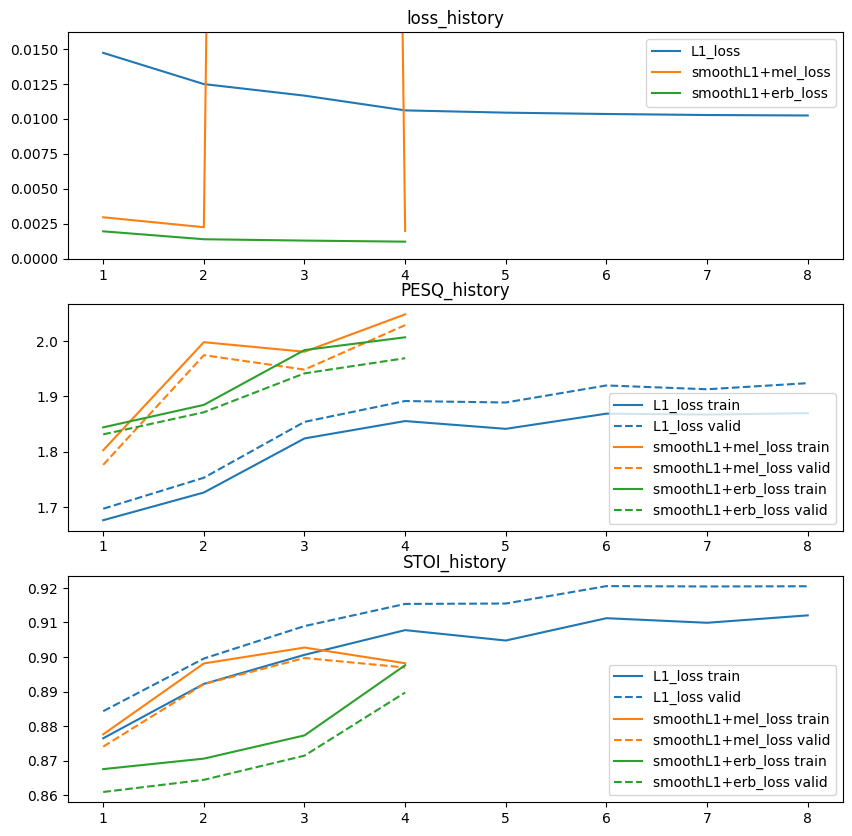

In [35]:
visualise_reports({'/content/drive/MyDrive/my_att_l1_noaug/log.json':'L1_loss',
                   '/content/drive/MyDrive/my_att_lsp3_noaug/log.json':'smoothL1+mel_loss',
                   '/content/drive/MyDrive/my_att_erb_noaug/log.json':'smoothL1+erb_loss'})